# DS 8001 — Lab 7: Recommender Systems

This lab measures **how much a recommender system gains from each idea in the lecture**, using the same held-out ratings throughout.

Problems 1 and 2 stay with collaborative filtering: how similarity between rating vectors should be measured, and how much an item-item neighbourhood method gains over simple baselines. In Problem 3 you implement the stochastic-gradient update of the latent factor model yourself and compare it with the neighbourhood method. Problem 4 studies overfitting and regularization, and Problem 5 asks what happens when an item has no ratings at all.

Everything after Problem 1 uses the same simulated rating matrix and the same evaluation function, so the numbers are directly comparable across problems.

### How to answer written questions

Whenever you are asked for a written prediction, explanation, or comparative analysis, **insert a new Markdown/text cell immediately after the question and type your answer there**. In Google Colab, use **+ Text**; in Jupyter, insert a new cell and change its type to **Markdown**. Do not put prose answers inside code cells or edit the question itself.

## Setup

Run the next cell first. It imports the packages used in the lab and defines `rmse`, the error measure used in every experiment:

$$RMSE = \sqrt{\frac{1}{|R|}\sum_{(x,i) \in R}(\hat r_{xi} - r_{xi})^2}$$

It returns `nan` when a method produced no predictions at all — a case we meet in Problem 5.

In [291]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def rmse(predictions, truths):
    """Root-mean-square error between two equal-length sequences of ratings."""
    if len(predictions) == 0:          # a method that could predict nothing at all
        return float("nan")
    predictions = np.asarray(predictions, dtype=float)
    truths = np.asarray(truths, dtype=float)
    return float(np.sqrt(np.mean((predictions - truths) ** 2)))

## Problem 1 — Measuring similarity between users

### **Problem Description**

The table below is the example from the lecture. Rows are users, columns are three Harry Potter films, one Twilight film and three Star Wars films; blanks are unknown ratings.

Users A and B are both Harry Potter fans: the only film they share is HP1 and they rate it alike. User C is a Star Wars fan who dislikes Twilight, whereas A likes Twilight and dislikes SW1 — they disagree on both films they share. A useful similarity measure should therefore report

$$sim(A,B) > sim(A,C)$$

### **Provided Methods**

The next cell defines the rating matrix and two of the three similarity measures from the lecture:

- `jaccard`: treats each user as the **set** of items they rated and ignores the rating values;
- `cosine_sim`: treats each user as a vector, with every unknown rating replaced by 0.

In [292]:
# Rows are users A-D, columns are items; np.nan marks an unknown rating.
users_small = ["A", "B", "C", "D"]
items_small = ["HP1", "HP2", "HP3", "TW", "SW1", "SW2", "SW3"]
ratings_small = np.array([
    [4.0,    np.nan, np.nan, 5.0,    1.0,    np.nan, np.nan],
    [5.0,    5.0,    4.0,    np.nan, np.nan, np.nan, np.nan],
    [np.nan, np.nan, np.nan, 2.0,    4.0,    5.0,    np.nan],
    [np.nan, 3.0,    np.nan, np.nan, np.nan, np.nan, 3.0   ],
])
display(pd.DataFrame(ratings_small, index=users_small, columns=items_small))


def jaccard(r1, r2):
    """Jaccard similarity of the two sets of rated items (rating values ignored)."""
    rated1, rated2 = ~np.isnan(r1), ~np.isnan(r2)
    return float((rated1 & rated2).sum() / (rated1 | rated2).sum())


def cosine_sim(r1, r2):
    """Cosine similarity with every unknown rating replaced by 0."""
    v1, v2 = np.nan_to_num(r1), np.nan_to_num(r2)
    return float(v1 @ v2 / (np.linalg.norm(v1) * np.linalg.norm(v2)))

,HP1,HP2,HP3,TW,SW1,SW2,SW3
A,4.0,NaN,NaN,5.0,1.0,NaN,NaN
B,5.0,5.0,4.0,NaN,NaN,NaN,NaN
C,NaN,NaN,NaN,2.0,4.0,5.0,NaN
D,NaN,3.0,NaN,NaN,NaN,NaN,3.0


### **Task Description**

1. Complete `centered_cosine` in the next cell. This is the third measure from the lecture: subtract from each user's vector the mean of that user's **observed** ratings, then take the cosine similarity of the two centered vectors with unknown entries treated as 0. (`np.nanmean` ignores `nan` entries, and `cosine_sim` already replaces `nan` by 0.)
2. In the cell after it, compute all three similarities for the pairs (A, B) and (A, C) and collect them in a small table with one row per measure.
3. Decide which measures order the two pairs correctly.

In [293]:
def centered_cosine(r1, r2):
    """Centered cosine (Pearson) similarity of two rating vectors.

    Step 1: subtract from each vector the mean of its own observed ratings.
    Step 2: return the cosine similarity of the two centered vectors.
    """
    # TODO: centre each vector on the mean of its observed ratings.
    r1_centered = r1 - np.nanmean(r1)
    r2_centered = r2 - np.nanmean(r2)
    # TODO: return the cosine similarity of the centered vectors.
    return cosine_sim(r1_centered, r2_centered)

In [294]:
A, B, C = ratings_small[0], ratings_small[1], ratings_small[2]

measures = {"Jaccard": jaccard, "cosine": cosine_sim, "centered cosine": centered_cosine}

# TODO: for each measure, compute the similarity of the pairs (A, B) and (A, C).
results = {}
for name, func in measures.items():
    sim_AB = func(A, B)
    sim_AC = func(A, C)
    results[name] = {"sim(A,B)": sim_AB, "sim(A,C)": sim_AC}

# TODO: collect the results in a DataFrame with one row per measure and the
#       columns "sim(A,B)" and "sim(A,C)", and display it.
import pandas as pd
df = pd.DataFrame.from_dict(results, orient="index")
display(df.style.format("{:.4f}"))

,"sim(A,B)","sim(A,C)"
Jaccard,0.2000,0.5000
cosine,0.3799,0.3220
centered cosine,0.0925,-0.5591


**Your comparative analysis:**  
_Add a new Markdown/text cell immediately below this question. Which measures rank the two pairs the wrong way round, and what is it about the blank entries that makes them do so? What does subtracting the user's own mean change? Write 2–3 sentences._

**Comparative analysis:**
_Jaccard ranks the pairs the wrong way round (0.2000 for A–B vs 0.5000 for A–C) because it only counts which items were rated and ignores the rating values, so A and C look similar just for sharing two films (TW and SW1) even though they disagree on both. Plain cosine gets the order right but only barely (0.3799 vs 0.3220), because every blank is treated as a 0 rating, which lets the single shared film HP1 dominate the score. Subtracting each user's own mean makes blanks neutral and turns each rating into "above or below this user's average", so A (likes TW, dislikes SW1) and C (the opposite) become clearly negative at -0.5591, while A–B stays positive at 0.0925._

## Problem 2 — Held-out evaluation: baselines vs. item-item CF

### **Problem Description**

We now need data and an evaluation protocol. The next cell simulates a small rating matrix of exactly the form the lecture assumes,

$$r_{xi} = \mu + b_x + b_i + q_i \cdot p_x + \text{noise}, \qquad \text{rounded to 1--5 stars}$$

with a global mean, a user bias, an item bias and a 3-factor user-item interaction. Only a popularity-skewed subset of the cells is ever observed, so the matrix is sparse and a few items collect most of the ratings.

Following the lecture, we evaluate by **hiding** a random 25% of the observed ratings. Every method is fitted on the remaining ("training") ratings only and scored on the hidden ones. Each method gets two numbers:

- **RMSE** over the hidden ratings it managed to predict;
- **coverage**, the fraction of hidden ratings for which it produced a prediction at all.

The generator also returns a TF-IDF-style keyword profile for each item; that output is not used until Problem 5.

In [295]:
def build_dataset(seed=8001, n_users=120, n_items=60, k_true=3, density=0.25,
                  test_frac=0.25, n_tags=12):
    """Simulate a sparse rating matrix and a train/test split.

    Returns
      R          : n_users x n_items array of ratings, np.nan where no rating exists
      train_mask : boolean array, True where a rating is visible for training
      test_pairs : (n_test, 2) array of (user, item) whose rating is hidden
      profiles   : n_items x n_tags array of TF-IDF-style keyword weights
    """
    rng = np.random.default_rng(seed)
    mu, sigma_factor, sigma_noise = 3.6, 0.75, 0.35

    # True parameters: biases and k_true latent factors per user and per item.
    b_user = rng.normal(0, 0.45, n_users)
    b_item = rng.normal(0, 0.55, n_items)
    P_true = rng.normal(0, sigma_factor, (n_users, k_true))
    Q_true = rng.normal(0, sigma_factor, (n_items, k_true))
    R_full = (mu + b_user[:, None] + b_item[None, :] + P_true @ Q_true.T
              + rng.normal(0, sigma_noise, (n_users, n_items)))
    R_full = np.clip(np.rint(R_full), 1, 5)            # 1-5 stars

    # Which cells are observed: popular items and active users are rated more often.
    popularity = rng.lognormal(0, 0.70, n_items); popularity /= popularity.sum()
    activity = rng.lognormal(0, 0.45, n_users); activity /= activity.sum()
    prob = np.outer(activity, popularity)
    prob = np.clip(prob / prob.sum() * density * n_users * n_items, 0, 0.95)
    mask = rng.random((n_users, n_items)) < prob

    # Guarantee a minimum amount of data per user and per item.
    for x in range(n_users):
        missing = 8 - mask[x].sum()
        if missing > 0:
            cand = np.flatnonzero(~mask[x])
            weights = popularity[cand] / popularity[cand].sum()
            mask[x, rng.choice(cand, missing, replace=False, p=weights)] = True
    for i in range(n_items):
        missing = 6 - mask[:, i].sum()
        if missing > 0:
            cand = np.flatnonzero(~mask[:, i])
            mask[rng.choice(cand, missing, replace=False), i] = True

    # Hide a fraction of the observed ratings, keeping every user and item in training.
    observed = np.argwhere(mask); rng.shuffle(observed)
    n_test = int(round(test_frac * len(observed)))
    train_mask, test_pairs = mask.copy(), []
    per_user, per_item = mask.sum(1).copy(), mask.sum(0).copy()
    for x, i in observed:
        if len(test_pairs) >= n_test:
            break
        if per_user[x] > 5 and per_item[i] > 4:
            train_mask[x, i] = False
            test_pairs.append((x, i))
            per_user[x] -= 1; per_item[i] -= 1

    # Item keyword profiles: 4 keywords per item, weighted TF-IDF style. They are
    # driven by the true item factors, so content and taste are related but not equal.
    W = rng.normal(0, 1.0, (k_true, n_tags))
    scores = Q_true @ W + rng.normal(0, 0.55, (n_items, n_tags))
    scores -= scores.min(axis=1, keepdims=True)
    profiles = np.zeros_like(scores)
    for i in range(n_items):
        profiles[i, np.argsort(-scores[i])[:4]] = scores[i, np.argsort(-scores[i])[:4]]
    profiles /= np.maximum(profiles.max(axis=1, keepdims=True), 1e-12)          # TF
    profiles *= np.log(n_items / np.maximum((profiles > 0).sum(axis=0), 1))     # x IDF

    R = np.where(mask, R_full, np.nan)
    return R, train_mask, np.array(test_pairs), profiles


R, train_mask, test_pairs, profiles = build_dataset()
n_users, n_items = R.shape

print(f"{n_users} users x {n_items} items = {n_users * n_items} cells")
print(f"observed ratings     : {int(np.sum(~np.isnan(R)))} "
      f"({np.mean(~np.isnan(R)):.1%} of all cells)")
print(f"training ratings     : {int(train_mask.sum())} "
      f"(median per user: {int(np.median(train_mask.sum(1)))})")
print(f"hidden test ratings  : {len(test_pairs)}")
print(f"mean training rating : {R[train_mask].mean():.3f}")

120 users x 60 items = 7200 cells
observed ratings     : 1764 (24.5% of all cells)
training ratings     : 1323 (median per user: 10)
hidden test ratings  : 441
mean training rating : 3.439


### **Provided Methods**

The next cell defines the three prediction rules we compare. Each is built by a small factory that returns a `predict(x, i)` function, so all three can be scored by the same code:

- `make_global_mean_predictor`: predicts the overall mean training rating $\mu$ in every cell;
- `make_baseline_predictor`: predicts the lecture's baseline $b_{xi} = \mu + b_x + b_i$, where $b_x$ and $b_i$ are the average deviations of user $x$ and item $i$ from $\mu$;
- `make_item_item_predictor`: item-item collaborative filtering,

$$\hat r_{xi} = b_{xi} + \frac{\sum_{j \in N(i;x)} s_{ij}\,(r_{xj} - b_{xj})}{\sum_{j \in N(i;x)} s_{ij}}$$

where $N(i;x)$ holds the $k$ items most similar to $i$ **among those user $x$ rated in the training data**, and $s_{ij}$ is the centered cosine of Problem 1 applied to the *item* rows of the matrix. Only positive similarities are kept, and the rule returns `nan` when user $x$ has rated no positively-similar item.

In [296]:
def fit_baseline(R, train_mask):
    """Estimate mu, b_x and b_i from the training ratings only."""
    mu = float(R[train_mask].mean())
    b_user, b_item = np.zeros(R.shape[0]), np.zeros(R.shape[1])
    for x in range(R.shape[0]):
        if train_mask[x].any():
            b_user[x] = R[x, train_mask[x]].mean() - mu      # user deviation
    for i in range(R.shape[1]):
        if train_mask[:, i].any():
            b_item[i] = R[train_mask[:, i], i].mean() - mu   # item deviation
    return mu, b_user, b_item


def make_global_mean_predictor(baseline):
    mu, _, _ = baseline
    return lambda x, i: mu


def make_baseline_predictor(baseline):
    mu, b_user, b_item = baseline
    return lambda x, i: float(np.clip(mu + b_user[x] + b_item[i], 1, 5))


def cosine_rows(M):
    """Cosine similarity between every pair of rows of M (self-similarity set to 0)."""
    norms = np.linalg.norm(M, axis=1)
    norms[norms == 0] = 1e-12
    S = (M @ M.T) / np.outer(norms, norms)
    np.fill_diagonal(S, 0.0)
    return S


def item_similarity(R, train_mask):
    """Centered-cosine similarity between items: Problem 1 applied to item rows."""
    C = np.zeros((R.shape[1], R.shape[0]))          # items x users, 0 where unrated
    for i in range(R.shape[1]):
        raters = train_mask[:, i]
        if raters.any():
            C[i, raters] = R[raters, i] - R[raters, i].mean()
    return cosine_rows(C)


def make_item_item_predictor(S, train_mask, baseline, k=5):
    """Item-item CF using the similarity matrix S and the given baseline."""
    mu, b_user, b_item = baseline

    def predict(x, i):
        rated = np.flatnonzero(train_mask[x])       # items x rated in training
        sims = S[i, rated]
        keep = sims > 0                             # negative weights are dropped
        rated, sims = rated[keep], sims[keep]
        if len(rated) == 0:
            return np.nan                           # no neighbour -> no prediction
        top = np.argsort(-sims)[:k]                 # the k most similar items
        rated, sims = rated[top], sims[top]
        deviations = R[x, rated] - (mu + b_user[x] + b_item[rated])
        pred = mu + b_user[x] + b_item[i] + sims @ deviations / sims.sum()
        return float(np.clip(pred, 1, 5))           # ratings live on a 1-5 scale

    return predict


baseline = fit_baseline(R, train_mask)
S_ratings = item_similarity(R, train_mask)
print("baseline: mu = %.3f, b_x in [%.2f, %.2f], b_i in [%.2f, %.2f]"
      % (baseline[0], baseline[1].min(), baseline[1].max(),
         baseline[2].min(), baseline[2].max()))
print("item-item similarities: min %.2f, max %.2f" % (S_ratings.min(), S_ratings.max()))

baseline: mu = 3.439, b_x in [-1.44, 1.19], b_i in [-1.02, 1.14]
item-item similarities: min -0.69, max 0.57


### **Task Description**

1. Complete `evaluate(predict_fn, pairs)` in the next cell. It calls `predict_fn(x, i)` on every hidden pair, keeps the predictions that are not `nan`, and returns the pair `(RMSE over those predictions, coverage)`.
2. Use it to score the three methods above (with $k = 5$ for the CF rule) and display a table with one row per method.
3. Then vary the neighbourhood size $k$ over the supplied values, record the CF RMSE for each, and plot RMSE against $k$.

In [297]:
def evaluate(predict_fn, pairs):
    """Score a prediction rule on a set of hidden (user, item) pairs.

    predict_fn(x, i) returns a predicted rating, or np.nan if the rule cannot
    predict that pair. The true rating of a hidden pair is R[x, i].

    Return (RMSE over the predicted pairs, coverage), where coverage is the
    fraction of pairs for which a prediction was produced.
    """
    # TODO: loop over the pairs, call predict_fn, and keep every prediction that
    #       is not nan together with the true rating.
    predictions, truths = [], []
    for x, i in pairs:
        pred = predict_fn(x, i)
        if not np.isnan(pred):
            predictions.append(pred)
            truths.append(R[x, i])
    # TODO: return the RMSE over the kept predictions and the coverage.
    return rmse(predictions, truths), len(predictions) / len(pairs)

In [298]:
methods = {
    "global mean": make_global_mean_predictor(baseline),
    "baseline mu + b_x + b_i": make_baseline_predictor(baseline),
    "item-item CF (k=5)": make_item_item_predictor(S_ratings, train_mask, baseline, k=5),
}

# TODO: evaluate every method on test_pairs.
results_2 = {}
for name, predict_fn in methods.items():
    test_rmse, coverage = evaluate(predict_fn, test_pairs)
    results_2[name] = {"test RMSE": test_rmse, "coverage": coverage}
# TODO: display a DataFrame with one row per method and the columns
#       "test RMSE" and "coverage".
results_df = pd.DataFrame.from_dict(results_2, orient="index")
display(results_df.style.format("{:.4f}"))

,test RMSE,coverage
global mean,1.0884,1.0000
baseline mu + b_x + b_i,0.9252,1.0000
item-item CF (k=5),0.7727,0.9864


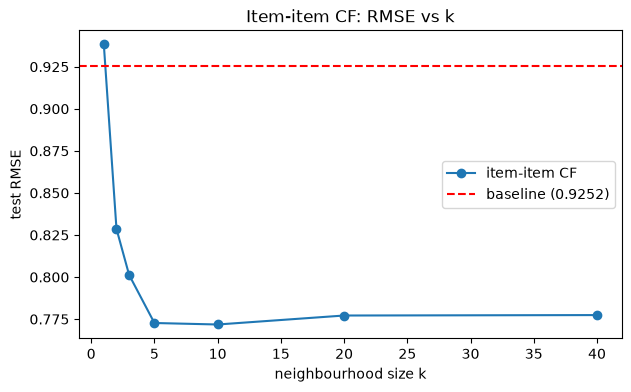

 k  CF RMSE
 1   0.9382
 2   0.8287
 3   0.8013
 5   0.7727
10   0.7718
20   0.7771
40   0.7774
Baseline RMSE: 0.9252


In [299]:
neighbourhood_sizes = [1, 2, 3, 5, 10, 20, 40]

cf_rmse = []

# TODO: for each k, build an item-item predictor with that neighbourhood size,
#       evaluate it on test_pairs, and store the RMSE in cf_rmse.
for k in neighbourhood_sizes:
    predict_k = make_item_item_predictor(S_ratings, train_mask, baseline, k=k)
    k_rmse, _ = evaluate(predict_k, test_pairs)
    cf_rmse.append(k_rmse)

# TODO: plot cf_rmse against neighbourhood_sizes. Also evaluate the baseline
#       once, store its RMSE as baseline_rmse, and draw it as a horizontal
#       reference line (plt.axhline); Problem 3 reuses that value.
baseline_rmse, _ = evaluate(make_baseline_predictor(baseline), test_pairs)

plt.figure(figsize=(7, 4))
plt.plot(neighbourhood_sizes, cf_rmse, marker="o", label="item-item CF")
plt.axhline(baseline_rmse, color="red", linestyle="--", label=f"baseline ({baseline_rmse:.4f})")
plt.xlabel("neighbourhood size k")
plt.ylabel("test RMSE")
plt.title("Item-item CF: RMSE vs k")
plt.legend()
plt.show()

print(pd.DataFrame({"k": neighbourhood_sizes, "CF RMSE": np.round(cf_rmse, 4)}).to_string(index=False))
print(f"Baseline RMSE: {baseline_rmse:.4f}")

**Your comparative analysis:**  
_Add a new Markdown/text cell immediately below this question. How much does each step (global mean → baseline → CF) buy, and what happens to the CF error for very small and for very large $k$? Write 2–3 sentences._

**Comparative analysis:**
_Replacing the global mean (RMSE 1.0884) with the baseline μ + b_x + b_i lowers the test RMSE to 0.9252, and item-item CF at k = 5 lowers it further to 0.7727, at the cost of slightly lower coverage (0.9864) because it returns no prediction when a user has no positively similar rated item. For very small k the CF error is poor (0.9382 at k = 1, worse than the baseline) because a single noisy neighbour drives the prediction. As k grows the error falls to its minimum around k = 10 (0.7718), then rises slightly (0.7774 at k = 40) as less similar items are averaged in._

## Problem 3 — Latent factor model: implementing the SGD update

### **Problem Description**

The latent factor model replaces the neighbourhood rule by learned factors. Each item gets a vector $q_i \in \mathbb{R}^k$ and each user a vector $p_x \in \mathbb{R}^k$ in the same space, and

$$\hat r_{xi} = \mu + b_x + b_i + q_i \cdot p_x$$

All of $P$, $Q$, $b_x$ and $b_i$ are estimated from the **observed** ratings only:

$$\min_{P,Q,b}\ \sum_{(x,i) \in R}\big(r_{xi} - \hat r_{xi}\big)^2 + \lambda\Big(\sum_x \|p_x\|^2 + \sum_i \|q_i\|^2 + \sum_x b_x^2 + \sum_i b_i^2\Big)$$

(the lecture uses a separate $\lambda$ for each group of parameters; a single common $\lambda$ keeps the experiments below readable).

Stochastic gradient descent visits one observed rating at a time and updates only the two vectors involved in it:

$$\xi_{xi} = 2\,(r_{xi} - \hat r_{xi}), \qquad q_i \leftarrow q_i + \eta\,(\xi_{xi}\, p_x - \lambda q_i), \qquad p_x \leftarrow p_x + \eta\,(\xi_{xi}\, q_i - \lambda p_x)$$

### **Provided Methods**

`train_mf` below runs the two loops of the lecture (over epochs, and over the ratings inside an epoch), performs the bias updates, and records the training and test RMSE after every epoch. The one piece it does not contain is the factor update: it calls `sgd_update`, which **you** write in Part A. `make_mf_predictor` wraps a fitted model in the same `predict(x, i)` interface as Problem 2, so it can be scored with your `evaluate` function.

In [300]:
def mask_to_triples(R, mask):
    """Turn a boolean mask into a list of (user, item, rating) triples."""
    return [(int(x), int(i), float(R[x, i])) for x, i in np.argwhere(mask)]


train_triples = mask_to_triples(R, train_mask)
test_triples = [(int(x), int(i), float(R[x, i])) for x, i in test_pairs]


def train_mf(train_triples, test_triples, n_users, n_items, k=4, lam=0.05,
             eta=0.01, epochs=40, with_bias=True, seed=0):
    """Fit R ~ Q P^T by stochastic gradient descent; calls your sgd_update."""
    rng = np.random.default_rng(seed)
    mu = float(np.mean([r for _, _, r in train_triples]))

    if with_bias:
        # The biases carry the overall level, so the factors may start near zero.
        P = rng.normal(0, 0.1, (n_users, k))
        Q = rng.normal(0, 0.1, (n_items, k))
    else:
        # Without bias terms the factors alone must reproduce the mean rating,
        # so they are started at a level for which q_i . p_x is about mu.
        start = np.sqrt(mu / k)
        P = start + rng.normal(0, 0.05, (n_users, k))
        Q = start + rng.normal(0, 0.05, (n_items, k))

    b_user, b_item = np.zeros(n_users), np.zeros(n_items)

    def predict_raw(x, i):
        return (mu + b_user[x] + b_item[i] if with_bias else 0.0) + P[x] @ Q[i]

    def score(triples):
        return rmse([np.clip(predict_raw(x, i), 1, 5) for x, i, _ in triples],
                    [r for _, _, r in triples])

    history, order = [], np.arange(len(train_triples))
    for epoch in range(epochs):
        rng.shuffle(order)                      # a different rating order each epoch
        for idx in order:
            x, i, r = train_triples[idx]
            err = 2.0 * (r - predict_raw(x, i))         # the lecture's xi_xi
            p_x, q_i = P[x].copy(), Q[i].copy()         # values before this step
            P[x], Q[i] = sgd_update(p_x, q_i, err, eta, lam)
            if with_bias:                               # bias updates are supplied
                b_user[x] += eta * (err - lam * b_user[x])
                b_item[i] += eta * (err - lam * b_item[i])
        history.append((score(train_triples), score(test_triples)))

    return dict(P=P, Q=Q, b_user=b_user, b_item=b_item, mu=mu,
                with_bias=with_bias, history=np.array(history))


def make_mf_predictor(model):
    """Wrap a fitted model into the predict(x, i) interface used in Problem 2."""
    P, Q, mu = model["P"], model["Q"], model["mu"]
    b_user, b_item, with_bias = model["b_user"], model["b_item"], model["with_bias"]

    def predict(x, i):
        pred = (mu + b_user[x] + b_item[i] if with_bias else 0.0) + P[x] @ Q[i]
        return float(np.clip(pred, 1, 5))

    return predict


print(f"{len(train_triples)} training triples, {len(test_triples)} test triples")

1323 training triples, 441 test triples


### **Task Description**

#### Part A — Implement the SGD update

Complete `sgd_update` in the next cell using the two update equations above. The argument `err` is $\xi_{xi}$, already computed by `train_mf`. Both equations use the **current** values of $p_x$ and $q_i$ on their right-hand sides, so compute both updated vectors before returning them, and return them in the order `(p_x, q_i)`.

In [301]:
def sgd_update(p_x, q_i, err, eta, lam):
    """One stochastic-gradient step for a single observed rating (x, i).

    p_x : current user factor vector (numpy array of length k)
    q_i : current item factor vector (numpy array of length k)
    err : the lecture's xi_xi = 2 * (r_xi - predicted rating)
    eta : learning rate
    lam : regularization parameter

    Return the updated (p_x, q_i).
    """
    # TODO: compute the updated item factor vector.
    q_new = q_i + eta * (err * p_x - lam * q_i)
    # TODO: compute the updated user factor vector.
    p_new = p_x + eta * (err * q_i - lam * p_x)

    # TODO: return the two updated vectors, user factor first.
    return p_new, q_new

#### Part B — Check that it trains

Fit a model with `k=4`, `lam=0.05` and the default 40 epochs, then

1. plot the two RMSE series stored in `model["history"]` (column 0 is training, column 1 is test) against the epoch number;
2. score the fitted model with your `evaluate` function and compare its test RMSE with the baseline and with the best item-item CF result of Problem 2.

If the training RMSE does not fall steadily below 0.6, fix Part A before continuing: Problem 4 reuses this function.

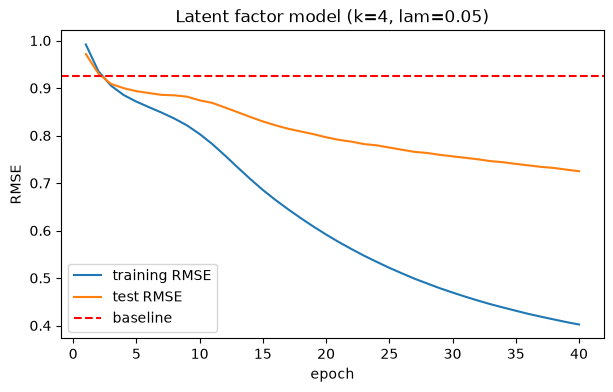

MF test RMSE: 0.7249, coverage: 1.0000
Baseline RMSE: 0.9252, best CF RMSE: 0.7718


In [302]:
model = train_mf(train_triples, test_triples, n_users, n_items, k=4, lam=0.05)

# TODO: plot model["history"][:, 0] (training) and model["history"][:, 1] (test)
#       against the epoch number, on the same figure.
epochs_axis = np.arange(1, len(model["history"]) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs_axis, model["history"][:, 0], label="training RMSE")
plt.plot(epochs_axis, model["history"][:, 1], label="test RMSE")
plt.axhline(baseline_rmse, color="red", linestyle="--", label="baseline")
plt.xlabel("epoch")
plt.ylabel("RMSE")
plt.title("Latent factor model (k=4, lam=0.05)")
plt.legend()
plt.show()
# TODO: print evaluate(make_mf_predictor(model), test_pairs).
mf_rmse, mf_coverage = evaluate(make_mf_predictor(model), test_pairs)
print(f"MF test RMSE: {mf_rmse:.4f}, coverage: {mf_coverage:.4f}")
print(f"Baseline RMSE: {baseline_rmse:.4f}, best CF RMSE: {min(cf_rmse):.4f}")

#### Part C — How much are the bias terms worth?

The lecture's performance figure claims that adding the bias terms $b_x, b_i$ buys more than a large increase in the number of factors. Test that claim: fit the model for `k` in `[1, 2, 4]`, once with `with_bias=True` and once with `with_bias=False`, and tabulate the final training and test RMSE (the last row of `model["history"]`) for the six runs. Each fit takes well under a second.

In [303]:
rows = []

# TODO: for each k in [1, 2, 4] and each setting of with_bias, fit a model with
#       lam=0.05 and record k, the bias setting, and the final train/test RMSE.
for k in [1, 2, 4]:
    for with_bias in [True, False]:
        fitted = train_mf(train_triples, test_triples, n_users, n_items,
                          k=k, lam=0.05, with_bias=with_bias)
        train_rmse, test_rmse = fitted["history"][-1]
        rows.append({"k": k, "with_bias": with_bias,
                     "train RMSE": train_rmse, "test RMSE": test_rmse})
# TODO: display the six runs as a DataFrame.
df_bias = pd.DataFrame(rows)
display(df_bias.style.format({"train RMSE": "{:.4f}", "test RMSE": "{:.4f}"}))

,k,with_bias,train RMSE,test RMSE
0,1,True,0.6525,0.7998
1,1,False,0.8715,0.9087
2,2,True,0.5160,0.7284
3,2,False,0.6722,0.8220
4,4,True,0.4021,0.7249
5,4,False,0.4542,0.7282


**Your comparative analysis:**  
_Add a new Markdown/text cell immediately below this question. How does the latent factor model compare with item-item CF from Problem 2, and how many factors does a model without biases need in order to match a model with biases? Write 2–3 sentences._

**Comparative analysis:**

_The latent factor model (k = 4, with biases) reaches a test RMSE of 0.7249, which beats the best item-item CF (0.7718 at k = 10) and the baseline (0.9252), so learned factors capture taste better than a neighbourhood average. Without bias terms the factors alone must also absorb the global mean and each user's and item's overall tendency, so a model without biases needs k = 4 (0.7282) to match what a biased model achieves with only k = 2 (0.7284), and it is still slightly behind the biased k = 4 model. At k = 1 the gap is largest (0.9087 without biases vs 0.7998 with), which supports the lecture's claim that the bias terms buy more than extra factors._

## Problem 4 — Overfitting and regularization

### **Problem Description**

A latent factor model with $k$ factors has $k(|X| + |S|)$ free parameters: with our 120 users and 60 items, $k = 16$ already means 2,880 parameters fitted to about 1,300 training ratings. The lecture warns that the training error keeps falling as $k$ grows while the test error starts to rise, and that the cure is not simply a small $k$ but the penalty $\lambda(\ldots)$, which shrinks the factors of users and items that have little data.

### **Provided Methods**

`fit_and_score(k, lam, with_bias=True)` refits the model and returns its final `(train RMSE, test RMSE)`, so each experiment below is a short loop.

In [304]:
def fit_and_score(k, lam, with_bias=True):
    """Fit a latent factor model and return its final (train RMSE, test RMSE)."""
    fitted = train_mf(train_triples, test_triples, n_users, n_items,
                      k=k, lam=lam, with_bias=with_bias)
    train_rmse, test_rmse = fitted["history"][-1]
    return float(train_rmse), float(test_rmse)

### **Task Description**

**Part A — number of factors.** For each `k` in `k_values`, call `fit_and_score(k, lam=0.05)`, collect both RMSE values, and plot the two series against `k` on the same figure.

**Part B — regularization.** Fix `k = 16` and repeat the experiment for each `lam` in `lam_values`; plot the two series against `lam`. (A logarithmic x-axis is convenient, but `lam = 0` cannot be shown on one.)

**Written prediction:** Before running Part A, add a new Markdown/text cell immediately below this question and predict in 1–2 sentences what the two curves will look like.

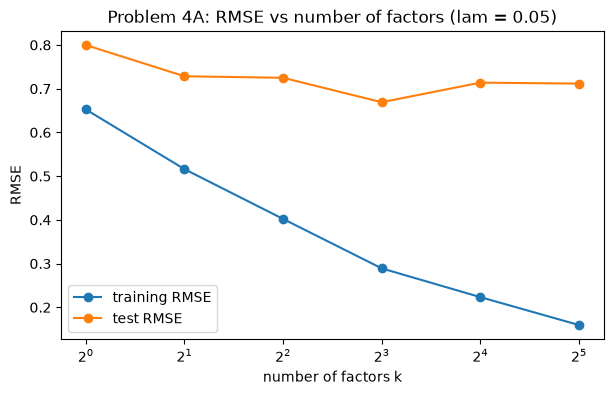

 k  train   test
 1 0.6525 0.7998
 2 0.5160 0.7284
 4 0.4021 0.7249
 8 0.2891 0.6691
16 0.2233 0.7139
32 0.1594 0.7116


In [305]:
k_values = [1, 2, 4, 8, 16, 32]

train_scores, test_scores = [], []

# TODO: for each k, call fit_and_score(k, lam=0.05) and store the two values.
for k in k_values:
    tr, te = fit_and_score(k, lam=0.05)
    train_scores.append(tr)
    test_scores.append(te)
# TODO: plot both series against k_values on the same figure.
plt.figure(figsize=(7, 4))
plt.plot(k_values, train_scores, marker="o", label="training RMSE")
plt.plot(k_values, test_scores, marker="o", label="test RMSE")
plt.xscale("log", base=2)
plt.xlabel("number of factors k")
plt.ylabel("RMSE")
plt.title("Problem 4A: RMSE vs number of factors (lam = 0.05)")
plt.legend()
plt.show()

print(pd.DataFrame({"k": k_values, "train": np.round(train_scores, 4),
                    "test": np.round(test_scores, 4)}).to_string(index=False))

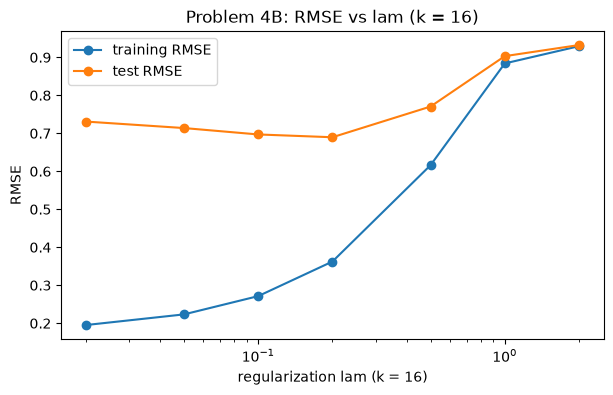

 lam  train   test
0.00 0.1781 0.7469
0.02 0.1952 0.7309
0.05 0.2233 0.7139
0.10 0.2714 0.6970
0.20 0.3624 0.6896
0.50 0.6161 0.7705
1.00 0.8840 0.9032
2.00 0.9294 0.9324


In [306]:
lam_values = [0.0, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0]

train_scores_lam, test_scores_lam = [], []

# TODO: for each lam, call fit_and_score(16, lam) and store the two values.
for lam in lam_values:
    tr, te = fit_and_score(16, lam)
    train_scores_lam.append(tr)
    test_scores_lam.append(te)
# TODO: plot both series against lam_values on the same figure.
plot_lams = [l for l in lam_values if l > 0]
plt.figure(figsize=(7, 4))
plt.plot(plot_lams, train_scores_lam[1:], marker="o", label="training RMSE")
plt.plot(plot_lams, test_scores_lam[1:], marker="o", label="test RMSE")
plt.xscale("log")
plt.xlabel("regularization lam (k = 16)")
plt.ylabel("RMSE")
plt.title("Problem 4B: RMSE vs lam (k = 16)")
plt.legend()
plt.show()

print(pd.DataFrame({"lam": lam_values, "train": np.round(train_scores_lam, 4),
                    "test": np.round(test_scores_lam, 4)}).to_string(index=False))

**Your comparative analysis:**  
_Add a new Markdown/text cell immediately below this question. Where is the test error smallest in each experiment, and what do the two curves do on either side of that point? Write 2–3 sentences._

**Comparative analysis:**

_In the number-of-factors experiment the test error is smallest at k = 8 (0.6691): the training error keeps falling all the way to k = 32 (0.1594), but the test error is worse on both sides of k = 8, higher for fewer factors (0.7998 at k = 1) and higher again for more (0.7139 at k = 16), a sign of overfitting. In the regularization experiment with k = 16 the test error is smallest at lam = 0.2 (0.6896): below it the model fits the training data very closely but generalizes worse (lam = 0 gives 0.1781 train vs 0.7469 test), while above it the penalty is so strong that both errors rise together (0.9032 test at lam = 1), a sign of underfitting. A well-chosen lam lets a large model (k = 16 at lam = 0.2) approach the best small-k result without having to choose k carefully._

## Problem 5 — Cold start: an item nobody has rated

### **Problem Description**

The lecture's concept check: a brand-new film enters the catalogue with zero ratings. Collaborative filtering computes $s_{ij}$ from columns of ratings, so it has nothing to work with; a content-based method compares *item profiles* and does not care whether the item has ever been rated.

### **Provided Methods**

The next cell makes the scenario concrete. Twelve items become "new releases": all of their **training** ratings are deleted, while their hidden test ratings are kept so that predictions for them can still be scored. Everything estimated from training data — the baseline and the rating-based item similarity — is refitted on the reduced matrix, and the hidden ratings are split into those of the new items (`cold_test_pairs`) and the rest (`warm_test_pairs`).

Both similarity matrices then feed the *same* item-item prediction rule of Problem 2; only the definition of $s_{ij}$ changes:

- `S_ratings_cold`: centered cosine between the item rows of the rating matrix (collaborative);
- `S_content`: cosine between the supplied TF-IDF keyword profiles of the items — the $\cos(m_1, m_3)$ computation of the lecture's TF-IDF example.

In [307]:
# Twelve items with at least four hidden ratings become "new releases".
rng_cold = np.random.default_rng(5)
test_counts = np.bincount(test_pairs[:, 1], minlength=n_items)
cold_items = np.sort(rng_cold.choice(np.flatnonzero(test_counts >= 4), size=12, replace=False))

train_mask_cold = train_mask.copy()
train_mask_cold[:, cold_items] = False            # delete their training ratings

# Anything fitted on training data must be refitted on the reduced matrix.
baseline_cold = fit_baseline(R, train_mask_cold)
S_ratings_cold = item_similarity(R, train_mask_cold)
S_content = cosine_rows(profiles)                 # content similarity needs no ratings

# Split the hidden ratings into those of the new items and the rest.
is_cold = np.isin(test_pairs[:, 1], cold_items)
cold_test_pairs, warm_test_pairs = test_pairs[is_cold], test_pairs[~is_cold]

print(f"new items          : {cold_items.tolist()}")
print(f"training ratings removed : {int(train_mask.sum() - train_mask_cold.sum())}")
print(f"hidden ratings     : {len(cold_test_pairs)} on new items, "
      f"{len(warm_test_pairs)} on the rest")
print(f"rating similarity of a new item to all others: "
      f"max {np.abs(S_ratings_cold[cold_items[0]]).max():.3f}")
print(f"content similarity of the same item          : "
      f"max {S_content[cold_items[0]].max():.3f}")

new items          : [0, 2, 13, 19, 20, 23, 31, 34, 38, 40, 55, 57]
training ratings removed : 282
hidden ratings     : 93 on new items, 348 on the rest
rating similarity of a new item to all others: max 0.000
content similarity of the same item          : max 0.880


### **Task Description**

1. Evaluate each of the three methods in the supplied `methods_cold` dictionary on `cold_test_pairs` and on `warm_test_pairs`.
2. Display one table with one row per method and four columns: RMSE and coverage on the new items, RMSE and coverage on the rest.
3. Note which entries are `nan`, and why.

In [308]:
methods_cold = {
    "baseline mu + b_x + b_i": make_baseline_predictor(baseline_cold),
    "CF, rating similarity": make_item_item_predictor(S_ratings_cold, train_mask_cold,
                                                      baseline_cold, k=5),
    "CF, content similarity": make_item_item_predictor(S_content, train_mask_cold,
                                                       baseline_cold, k=5),
}

# TODO: evaluate every method on cold_test_pairs and on warm_test_pairs.
results_cold = {}
for name, predict_fn in methods_cold.items():
    rmse_new, cov_new = evaluate(predict_fn, cold_test_pairs)
    rmse_rest, cov_rest = evaluate(predict_fn, warm_test_pairs)
    results_cold[name] = {"RMSE (new)": rmse_new, "coverage (new)": cov_new,
                          "RMSE (rest)": rmse_rest, "coverage (rest)": cov_rest}
# TODO: display a DataFrame with one row per method and the four columns
#       "RMSE (new)", "coverage (new)", "RMSE (rest)", "coverage (rest)".
df_cold = pd.DataFrame(results_cold).T
display(df_cold.style.format({"RMSE (new)": "{:.4f}", "coverage (new)": "{:.4f}",
                             "RMSE (rest)": "{:.4f}", "coverage (rest)": "{:.4f}"}))


,RMSE (new),coverage (new),RMSE (rest),coverage (rest)
baseline mu + b_x + b_i,1.0151,1.0000,0.9633,1.0000
"CF, rating similarity",nan,0.0000,0.8181,0.9885
"CF, content similarity",0.8547,1.0000,0.8579,1.0000


**Your comparative analysis:**  
_Add a new Markdown/text cell immediately below this question. Which method can serve the new items and why, and which similarity is better on the items that do have ratings? What does this suggest about how a real system should be built? Write 2–3 sentences._

**Comparative analysis:**

_Only the baseline (RMSE 1.0151) and the content-similarity CF (0.8547) can serve the new items: rating-similarity CF has coverage 0.0 and an RMSE of NaN because an item with no ratings has zero rating-similarity to every other item, while content similarity only needs the item's keyword profile. On the items that do have ratings, rating similarity is better (0.8181 vs 0.8579) because it captures actual taste, whereas keywords are only a noisy proxy for it. A real system should therefore combine them, using content-based similarity for cold-start items and switching to collaborative filtering once enough ratings have accumulated._

## Final takeaway

Scored on the same hidden ratings, the five problems produced one ordered story: global mean ≈ 1.09 → baseline $\mu + b_x + b_i$ ≈ 0.93 → item-item CF ≈ 0.77 → latent factors ≈ 0.67–0.73. Each step buys less than the one before it, and each buys it in a different way: the baseline from *who* is rating and *what* is being rated, the neighbourhood from *which items behave alike*, and the factors from a compact description of both.

Two warnings came with it. The more expressive model is only useful with a well-chosen $\lambda$ (Problem 4), and every method that learns from ratings alone goes silent exactly where a new item enters the catalogue (Problem 5).

The question to carry forward is therefore not "which recommender is best?" but "what information does this method use, what does it do when that information is missing, and how much does it actually buy over a cheap baseline?"